Comparing sequences is the single most-used operation in bioinformatics. "What is this gene?" is answered by aligning it against known genes. "How related are these two species?" is a question about alignment. "Does this patient's virus carry a resistance mutation?" needs the patient's sequence lined up against a reference. This chapter builds the alignment algorithms from nothing, so you understand exactly what tools like BLAST are doing, and why their scores mean what they mean.

:::eli5
Aligning two sequences means sliding them against each other and inserting gaps until their matching letters line up, like comparing two slightly different editions of the same book paragraph by paragraph. You score every way of doing this, matches earn points, mismatches and gaps lose them, and keep the highest-scoring arrangement. The clever part is that you don't try all the astronomically many arrangements; a grid-filling trick (dynamic programming) finds the best one quickly.
:::

## The problem, and why it is hard

Given two sequences, we want to line them up, allowing **gaps** (insertions or deletions, collectively **indels**), to maximise a score that rewards matches and penalises mismatches and gaps. The trouble is that the number of possible alignments is astronomical: for two sequences of length 100 it exceeds 10⁷⁵. We cannot enumerate them. Dynamic programming finds the best one in time proportional to the product of the lengths.

The key insight: the best alignment of two sequences ending at positions $i$ and $j$ must end in one of three ways, and each extends a shorter best alignment we have already computed.

:::math
Let $A$ and $B$ be the sequences and $H_{i,j}$ the best score aligning $A_{1..i}$ with $B_{1..j}$. Then

$$H_{i,j} = \max \begin{cases} H_{i-1,j-1} + s(A_i, B_j) & \text{match or mismatch} \\ H_{i-1,j} + g & \text{gap in }B \\ H_{i,j-1} + g & \text{gap in }A \end{cases}$$

where $s$ scores a pair of letters and $g$ is the gap penalty. Fill the grid row by row, remember which choice won in each cell, then **trace back** from the corner to read off the alignment. This is **Needleman–Wunsch** (1970) for global alignment.
:::

The playground builds this grid live. Type two sequences, set the scores, and watch the best path.

::playground animations/align_lab.html 640

## Needleman–Wunsch in code

Let's implement global alignment ourselves, returning both the score and the alignment:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

def needleman_wunsch(A, B, match=2, mismatch=-1, gap=-2):
    n, m = len(A), len(B)
    H = np.zeros((n + 1, m + 1))
    H[:, 0] = np.arange(n + 1) * gap
    H[0, :] = np.arange(m + 1) * gap
    tb = np.zeros((n + 1, m + 1), dtype="U1")
    tb[1:, 0] = "U"; tb[0, 1:] = "L"
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            diag = H[i - 1, j - 1] + (match if A[i - 1] == B[j - 1] else mismatch)
            up, left = H[i - 1, j] + gap, H[i, j - 1] + gap
            H[i, j] = max(diag, up, left)
            tb[i, j] = "D" if H[i, j] == diag else ("U" if H[i, j] == up else "L")
    # traceback
    a, b, i, j = "", "", n, m
    while i > 0 or j > 0:
        d = tb[i, j]
        if d == "D": a, b, i, j = A[i-1] + a, B[j-1] + b, i-1, j-1
        elif d == "U": a, b, i = A[i-1] + a, "-" + b, i-1
        else: a, b, j = "-" + a, B[j-1] + b, j-1
    return H[n, m], a, b

score, a, b = needleman_wunsch("GATTACA", "GCATGCU".replace("U", "A"))
mid = "".join("|" if x == y else " " for x, y in zip(a, b))
print(f"score {score:.0f}")
print(a); print(mid); print(b)

score 5
GATTACA
|  | ||
GCATGCA


That is the whole algorithm in about 20 lines. It is $O(nm)$ in time and memory, fine for genes and proteins (hundreds to thousands of letters), but too slow and memory-hungry for whole genomes, which is why real tools use faster, approximate methods (later in this chapter).

## Local alignment: Smith–Waterman

Global alignment forces the two sequences to line up end to end. Often we instead want the best-matching *region* inside two otherwise different sequences, for example a shared domain in two proteins, or where a short read sits in a genome. **Smith–Waterman** (1981) changes two things: any cell that would go negative is reset to 0 (so an alignment can start fresh anywhere), and traceback starts from the highest-scoring cell and stops at the first 0.

In [2]:
def smith_waterman(A, B, match=3, mismatch=-3, gap=-2):
    n, m = len(A), len(B)
    H = np.zeros((n + 1, m + 1))
    best, bi, bj = 0, 0, 0
    tb = np.zeros((n + 1, m + 1), dtype="U1")
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            diag = H[i - 1, j - 1] + (match if A[i - 1] == B[j - 1] else mismatch)
            up, left = H[i - 1, j] + gap, H[i, j - 1] + gap
            H[i, j] = max(0, diag, up, left)
            tb[i, j] = "D" if H[i, j] == diag else ("U" if H[i, j] == up else ("L" if H[i, j] == left else ""))
            if H[i, j] >= best: best, bi, bj = H[i, j], i, j
    a, b, i, j = "", "", bi, bj
    while i > 0 and j > 0 and H[i, j] > 0:
        d = tb[i, j]
        if d == "D": a, b, i, j = A[i-1] + a, B[j-1] + b, i-1, j-1
        elif d == "U": a, b, i = A[i-1] + a, "-" + b, i-1
        else: a, b, j = "-" + a, B[j-1] + b, j-1
    return best, a, b

score, a, b = smith_waterman("AAAGGGTTTCCCAAA", "TTTCCCGGG")
print(f"best local score {score:.0f}")
print(a); print(b)

best local score 18
TTTCCC
TTTCCC


The playground's first tab lets you flip between global and local and watch the grid and path change. Global stretches the alignment corner to corner; local lights up only the shared block. Switching mode on two sequences that share a middle but differ at the ends is the clearest way to feel the difference.

## Scoring proteins properly: substitution matrices

For DNA, a flat match/mismatch score is reasonable. For proteins it is not, because amino acids are not equally interchangeable (prerequisite P5): replacing leucine with isoleucine (both hydrophobic) barely changes a protein, while replacing it with charged aspartate often breaks it. A good score should reflect how often each substitution actually happens in related proteins.

That is what a **substitution matrix** encodes. The **BLOSUM62** matrix, built from blocks of aligned protein families, gives a log-odds score for every amino-acid pair: positive if the pair is seen in related proteins more than chance, negative if less.

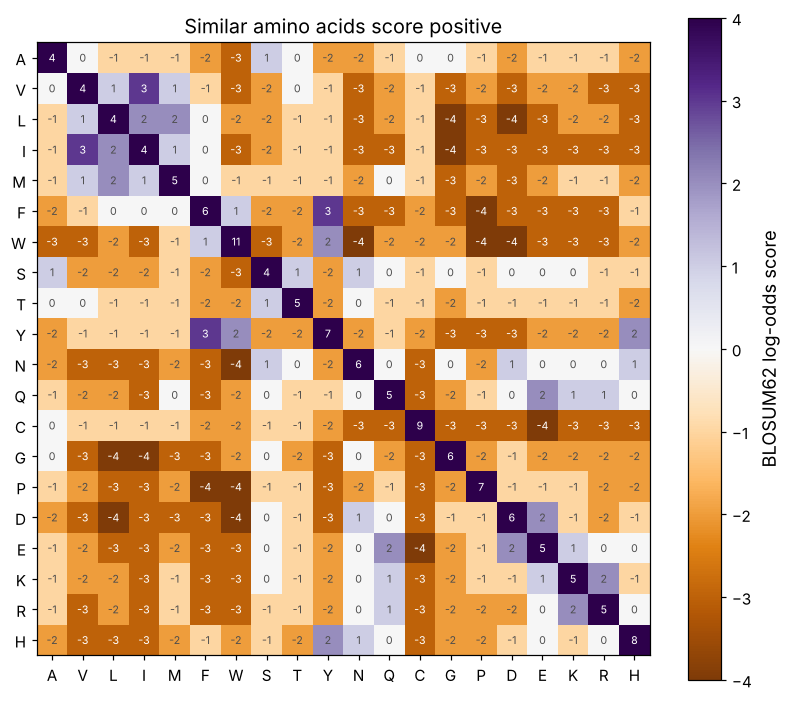

L vs I (both hydrophobic): 2 | L vs D (hydrophobic vs charged): -4
W vs W (rare, conserved): 11 | A vs A (common): 4


In [3]:
from Bio.Align import substitution_matrices
blosum = substitution_matrices.load("BLOSUM62")
aa = "AVLIMFWSTYNQCGPDEKRH"
mat = np.array([[blosum[x, y] for y in aa] for x in aa])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(mat, cmap="PuOr", vmin=-4, vmax=4)
ax.set_xticks(range(len(aa)), aa); ax.set_yticks(range(len(aa)), aa)
for i in range(len(aa)):
    for j in range(len(aa)):
        ax.text(j, i, int(mat[i, j]), ha="center", va="center", fontsize=7, color="white" if abs(mat[i, j]) > 2 else "0.3")
plt.colorbar(im, ax=ax, label="BLOSUM62 log-odds score"); ax.set_title("Similar amino acids score positive")
save_fig("blosum"); plt.show()
print("L vs I (both hydrophobic):", int(blosum["L", "I"]), "| L vs D (hydrophobic vs charged):", int(blosum["L", "D"]))
print("W vs W (rare, conserved):", int(blosum["W", "W"]), "| A vs A (common):", int(blosum["A", "A"]))
R["li"] = int(blosum["L", "I"]); R["ld"] = int(blosum["L", "D"]); R["ww"] = int(blosum["W", "W"])

![Figure 2-1. The BLOSUM62 substitution matrix, ordered so chemically similar amino acids are adjacent. Positive blocks appear among hydrophobic residues (top left) and among charged ones; most cross-type substitutions score negative.](images/blosum.png)

Matching leucine to isoleucine scores +2; leucine to aspartate scores -4. A conserved tryptophan matching itself scores +11 (it is rare and rarely substituted), far more than a common alanine match. Using BLOSUM62 instead of a flat score is what lets alignment detect distant evolutionary relationships where few residues are identical but many are *similar*.

:::bio
There is a family of matrices (BLOSUM45, 62, 80; and the older PAM series). Lower BLOSUM numbers suit more distant relationships, higher numbers closer ones. BLOSUM62 is the default for protein BLAST because it works well across a wide range. Gap penalties matter too: real alignments use an **affine** gap cost (a large penalty to *open* a gap, a small one to *extend* it), because one 5-residue insertion is far more likely than five separate 1-residue insertions.
:::

## A real alignment: SARS-CoV-1 vs SARS-CoV-2 spike

Let's align two real proteins: the spike glycoprotein of the original SARS virus (2003) and of SARS-CoV-2 (2019), the protein that vaccines target (prerequisites P5, P10). We use Biopython's aligner with BLOSUM62 and affine gaps, the same ingredients, just optimised.

lengths: SARS 1255, SARS-2 1273
alignment length 1277, identity 970/1251 = 78%, gap columns 26


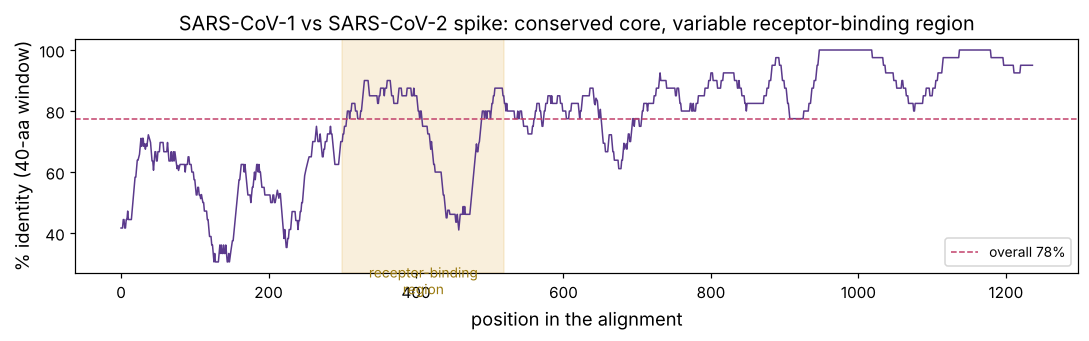

In [4]:
from Bio import SeqIO, Align
def read_seq(path):
    return str(SeqIO.read(path, "fasta").seq)

spike1 = read_seq("datasets/spike_sars1.fasta")
spike2 = read_seq("datasets/spike_sars2.fasta")
aligner = Align.PairwiseAligner(scoring="blastp")       # BLOSUM62 + affine gaps, like protein BLAST
aln = aligner.align(spike1, spike2)[0]
s1, s2 = str(aln[0]), str(aln[1])
ident = sum(x == y and x != "-" for x, y in zip(s1, s2))
aligned_cols = sum(x != "-" and y != "-" for x, y in zip(s1, s2))
gaps = sum(x == "-" or y == "-" for x, y in zip(s1, s2))
print(f"lengths: SARS {len(spike1)}, SARS-2 {len(spike2)}")
print(f"alignment length {len(s1)}, identity {ident}/{aligned_cols} = {ident / aligned_cols:.0%}, gap columns {gaps}")
R["spike_id"] = f"{ident / aligned_cols:.0%}"; R["spike_gaps"] = gaps

# identity in a sliding window along the alignment: where are the two spikes most and least similar?
w = 40
win_id = []
for i in range(0, len(s1) - w):
    cols = [(x, y) for x, y in zip(s1[i:i+w], s2[i:i+w]) if x != "-" and y != "-"]
    win_id.append(np.mean([x == y for x, y in cols]) if cols else np.nan)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(100 * np.array(win_id), color="#5b3a8c", lw=1)
ax.axhline(100 * ident / aligned_cols, color="#c2416b", ls="--", lw=1, label=f"overall {ident/aligned_cols:.0%}")
ax.axvspan(300, 520, color="#d99a14", alpha=0.15); ax.text(410, 20, "receptor-binding\nregion", ha="center", fontsize=9, color="#9a7a10")
ax.set_xlabel("position in the alignment"); ax.set_ylabel("% identity (40-aa window)"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("SARS-CoV-1 vs SARS-CoV-2 spike: conserved core, variable receptor-binding region")
save_fig("spike_align"); plt.show()
R["min_win"] = f"{100 * np.nanmin(win_id):.0f}"

![Figure 2-2. Sliding-window identity along the aligned spike proteins. Overall about three-quarters identical, but the front of the protein (N-terminal domain and receptor-binding region, which antibodies target) is markedly more variable than the conserved fusion machinery in the back half.](images/spike_align.png)

The two spikes are about 78% identical overall, but the identity is far from uniform. The front half (the N-terminal domain and the receptor-binding region, which grip the host cell and are the main antibody targets) is patchy, dipping to around 31% in places, while the back half (the fusion machinery that drives entry into the cell) is nearly identical. The parts under the strongest and most varied selection change fastest; the mechanical core, which simply has to work, is conserved. Alignment makes that contrast visible at a glance, and the same analysis run across thousands of genomes is how new variants are tracked.

## Dot plots: seeing alignment at a glance

Before (or instead of) a full alignment, a **dot plot** gives an instant visual comparison: put one sequence on each axis and mark every position where a short window matches. A continuous diagonal means similarity; a shifted diagonal means an indel; parallel diagonals mean repeats or duplications.

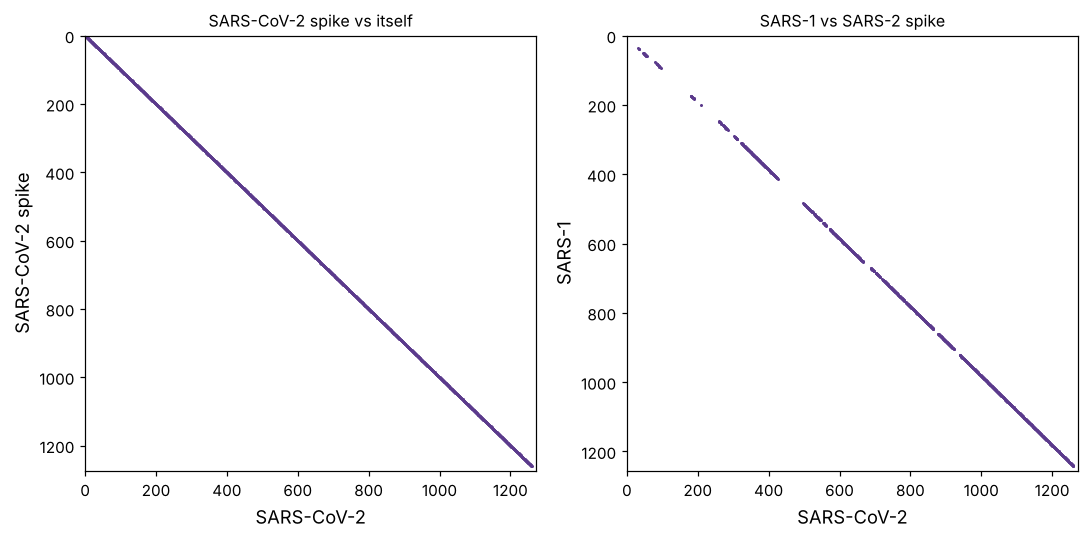

In [5]:
def dot_plot(A, B, w=10, thresh=8):
    n, m = len(A), len(B)
    pts = [(j, i) for i in range(n - w) for j in range(m - w)
           if sum(A[i+k] == B[j+k] for k in range(w)) >= thresh]
    return np.array(pts) if pts else np.empty((0, 2))

# compare the spike protein with itself to reveal internal repeats, and with its partner
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
for ax, (A, B, title) in zip(axs, [(spike2, spike2, "SARS-CoV-2 spike vs itself"), (spike1, spike2, "SARS-1 vs SARS-2 spike")]):
    pts = dot_plot(A, B, w=12, thresh=9)
    if len(pts):
        ax.scatter(pts[:, 0], pts[:, 1], s=1, color="#5b3a8c")
    ax.set_title(title, fontsize=10.5); ax.set_xlabel("SARS-CoV-2" if "itself" in title else "SARS-CoV-2"); ax.set_ylabel(title.split(" vs ")[0] if "vs" in title else "")
    ax.set_xlim(0, len(B)); ax.set_ylim(len(A), 0)
save_fig("dotplot"); plt.show()

![Figure 2-3. Left: the spike protein against itself shows the main diagonal plus faint off-diagonal signals from short internal repeats. Right: SARS-1 against SARS-2 is a near-continuous diagonal (highly similar), broken by small indels.](images/dotplot.png)

The second tab of the playground is an interactive dot plot; edit the text to insert, delete or repeat a section and watch the diagonal break or echo.

## Searching databases: the BLAST idea

Dynamic programming is exact but too slow to compare one query against the hundreds of billions of letters in GenBank. **BLAST** (Basic Local Alignment Search Tool, 1990, one of the most-cited papers in all of science) trades a little sensitivity for enormous speed with a **seed-and-extend** strategy:

1. **Seed**: break the query into short **words** (k-mers; 11 bases for DNA, 3 residues for protein) and find database positions where a word matches (a quick hash lookup, not alignment).
2. **Extend**: only around those seeds, run a local alignment (Smith–Waterman-like), stopping when the score drops.
3. **Score**: report hits with a statistical significance, the **E-value**: the number of hits this good expected by chance in a database this size. Small E-value (say < 10⁻⁵) means a real relationship.

Why seeding works: truly related sequences almost always share at least one exact short word, so you can skip the vast majority of the database that shares none. Let's measure how much work that saves.

In [6]:
def count_shared_words(query, db, k=11):
    qwords = {query[i:i+k] for i in range(len(query) - k + 1)}
    hits = sum(1 for j in range(len(db) - k + 1) if db[j:j+k] in qwords)
    return len(qwords), hits

# use the SARS-CoV-2 genome as a 'database' and a 400-base gene fragment as the query
genome = str(SeqIO.read("datasets/sarscov2.gb", "genbank").seq)
rng = np.random.default_rng(0)
start = 21600
query = genome[start:start + 400]
random_query = "".join(rng.choice(list("ACGT"), 400))
for name, q in [("real gene fragment", query), ("random sequence", random_query)]:
    nwords, hits = count_shared_words(q, genome, k=11)
    print(f"{name:20s}: {nwords} query words, {hits} seed hits in the genome ({100 * hits / (len(genome)):.3f}% of positions)")
seeds = count_shared_words(query, genome, 11)[1]
R["seed_positions"] = f"{100 * seeds / len(genome):.3f}"

real gene fragment  : 386 query words, 393 seed hits in the genome (1.314% of positions)
random sequence     : 390 query words, 6 seed hits in the genome (0.020% of positions)


The real fragment seeds at its true location (and a few short repeats); random sequence of the same length seeds almost nowhere. BLAST runs its expensive alignment only at those few seed positions instead of all 30,000, and against the real GenBank that ratio is millions to one. That is why a BLAST search of a gene against the entire database returns in seconds.

:::idea
Alignment scores need statistics. A score of 80 is meaningless until you know how often random sequences score 80 against a database that size. BLAST's **E-value** answers exactly that, using the theory that top local-alignment scores follow an extreme-value (Gumbel) distribution. Whenever you read "this hit has E = 1e-40", it means: you would expect 10⁻⁴⁰ hits this strong by chance, so it is almost certainly real. Always judge alignments by their E-value, not raw percent identity.
:::

## Multiple sequence alignment

Aligning *many* sequences at once (a **multiple sequence alignment**, MSA) reveals which positions are conserved across a whole family, the raw material for the next chapter's trees, for finding functional sites, and for the evolutionary input that powers AlphaFold (chapter 10). Doing it optimally is computationally intractable for many sequences, so tools (MUSCLE, MAFFT, Clustal) build MSAs progressively: align the most similar pairs first, then merge. Let's align the five human globin chains (α, β, and the embryonic/fetal δ, ε, γ chains, all paralogs from one ancestral gene, prerequisite P8) and look at conservation.

In [7]:
globins = list(SeqIO.parse("datasets/globins.fasta", "fasta"))
print(f"{len(globins)} globins: {[g.id.split('|')[-1] for g in globins]}")
# a quick progressive-ish view: align each to the first (human beta-globin) and stack identity
ref = str(globins[1].seq)
aligner2 = Align.PairwiseAligner(scoring="blastp")
print("\npairwise identity to human beta-globin:")
for g in globins:
    aln = aligner2.align(ref, str(g.seq))[0]
    s1, s2 = str(aln[0]), str(aln[1])
    cols = [(x, y) for x, y in zip(s1, s2) if x != "-" and y != "-"]
    idp = np.mean([x == y for x, y in cols])
    print(f"  {g.description.split('OS=')[0][:40]:40s} {idp:.0%}")

5 globins: ['HBA_HUMAN', 'HBB_HUMAN', 'HBE_HUMAN', 'HBG1_HUMAN', 'HBD_HUMAN']

pairwise identity to human beta-globin:
  sp|P69905|HBA_HUMAN Hemoglobin subunit a 45%
  sp|P68871|HBB_HUMAN Hemoglobin subunit b 100%
  sp|P02100|HBE_HUMAN Hemoglobin subunit e 76%
  sp|P69891|HBG1_HUMAN Hemoglobin subunit  73%
  sp|P02042|HBD_HUMAN Hemoglobin subunit d 93%


These chains share the same fold and the haem pocket despite ranging from 100% down to about 45% identity with β-globin (α-globin is the most diverged, as expected for the oldest duplication, prerequisite P8). An MSA lines up the handful of absolutely conserved positions, chiefly the histidine that holds the haem iron (prerequisite P5). Conserved columns in an MSA are nature pointing at the residues that matter.

## Summary

| Idea | One line |
|---|---|
| Dynamic programming | fill a grid of best sub-alignment scores; trace back for the alignment |
| Needleman–Wunsch | global alignment, end to end |
| Smith–Waterman | local alignment; reset negatives to 0, find the best region |
| Substitution matrix | BLOSUM/PAM: log-odds scores reflecting real substitution rates |
| Affine gaps | open penalty + smaller extend penalty |
| Dot plot | quick visual comparison; diagonals = similarity, breaks = indels |
| BLAST | seed with k-mer words, extend locally; E-value for significance |
| MSA | align a whole family; conserved columns mark important residues |

:::check
1. Why can't we align two 200-residue proteins by trying every possible alignment? *(The number of alignments is astronomically large; dynamic programming avoids enumerating them.)*
2. What is the key difference between Needleman–Wunsch and Smith–Waterman? *(Global vs local: Smith–Waterman resets negatives to 0 and keeps the best-scoring region.)*
3. Why use BLOSUM62 instead of a simple match/mismatch score for proteins? *(Amino acids substitute at very different rates; the matrix rewards chemically conservative changes, detecting distant homology.)*
4. Why does BLAST seed with exact short words first? *(Related sequences almost always share a short exact word, so it can skip the vast majority of the database cheaply.)*
5. A BLAST hit has 95% identity but E = 2. Is it significant? *(No: E = 2 means two such hits are expected by chance; short high-identity matches can be random.)*
:::

:::exercise
Add **affine gap penalties** to the Needleman–Wunsch function (open = −10, extend = −1) by tracking three matrices (match, gap-in-A, gap-in-B). Align the two spike proteins with (a) a flat gap of −2 per position and (b) affine gaps, and compare the number and length of gaps. Which looks more biologically realistic?
:::

<details><summary>Solution</summary>

In [8]:
def nw_affine(A, B, sub, open_pen=-10, ext_pen=-1):
    from Bio.Align import substitution_matrices
    n, m = len(A), len(B)
    NEG = -1e9
    M = np.full((n+1, m+1), NEG); Ia = np.full((n+1, m+1), NEG); Ib = np.full((n+1, m+1), NEG)
    M[0, 0] = 0
    for i in range(1, n+1): Ib[i, 0] = open_pen + (i-1) * ext_pen
    for j in range(1, m+1): Ia[0, j] = open_pen + (j-1) * ext_pen
    for i in range(1, n+1):
        for j in range(1, m+1):
            s = sub[A[i-1], B[j-1]]
            M[i, j] = max(M[i-1, j-1], Ia[i-1, j-1], Ib[i-1, j-1]) + s
            Ia[i, j] = max(M[i, j-1] + open_pen, Ia[i, j-1] + ext_pen)
            Ib[i, j] = max(M[i-1, j] + open_pen, Ib[i-1, j] + ext_pen)
    return max(M[n, m], Ia[n, m], Ib[n, m])

blosum = substitution_matrices.load("BLOSUM62")
print("affine-gap score:", nw_affine(spike1[:300], spike2[:300], blosum))

affine-gap score: 793.0


With a flat gap penalty, one real deletion of length 5 is penalised five times as much as a single mismatch, so the aligner avoids long gaps and instead scatters many short ones, often misplacing residues. Affine gaps charge most of the cost once (opening), so a single clean 5-residue gap is cheap: the alignment then uses a few long, biologically plausible indels instead of many scattered ones. This matters because real insertions and deletions usually affect several adjacent residues at once (a loop lengthening, an exon changing), which is why every production aligner uses affine gaps.

</details>